# MINI PROJECT  ---  SALES DATA ANALYSIS

STEP 1 – IMPORTING REQUIRED LIBRARIES

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

STEP 2 – LOADING THE DATASET

In [2]:
df = pd.read_csv("/content/sales_dataset_300.csv")
print(df)

    Order_ID  Order_Date Customer_Name       Product_Name     Category  \
0    ORD1111  2025-01-07    Ananya Das         Face Serum       Beauty   
1    ORD1070  2025-01-13   Meera Singh       Cookware Set         Home   
2    ORD1143  2025-01-13      Isha Rao              Novel        Books   
3    ORD1171  2025-01-13  Aditya Gupta   Wireless Earbuds  Electronics   
4    ORD1204  2025-01-15  Aditya Mehta  Bluetooth Speaker  Electronics   
..       ...         ...           ...                ...          ...   
295  ORD1083  2026-12-19  Suresh Reddy         Smartwatch  Electronics   
296  ORD1087  2026-12-23  Meera Sharma           Cookbook        Books   
297  ORD1292  2026-12-25   Rahul Mehta           Cookbook        Books   
298  ORD1105  2026-12-28  Suresh Patel         Power Bank  Electronics   
299  ORD1058  2026-12-30   Kavya Reddy         Hair Dryer       Beauty   

          City  Quantity  Unit_Price  Sales   Profit  
0         Pune         2         799   1598   423.45  
1

STEP 3 – EXPLORING THE DATASET

In [3]:
df.head()

,Order_ID,Order_Date,Customer_Name,Product_Name,Category,City,Quantity,Unit_Price,Sales,Profit
0,ORD1111,2025-01-07,Ananya Das,Face Serum,Beauty,Pune,2,799,1598,423.45
1,ORD1070,2025-01-13,Meera Singh,Cookware Set,Home,Pune,3,3299,9897,1227.31
2,ORD1143,2025-01-13,Isha Rao,Novel,Books,Delhi,1,399,399,83.29
3,ORD1171,2025-01-13,Aditya Gupta,Wireless Earbuds,Electronics,Delhi,1,2499,2499,501.03
4,ORD1204,2025-01-15,Aditya Mehta,Bluetooth Speaker,Electronics,Mumbai,2,1999,3998,824.26


In [4]:
df.shape

(300, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       300 non-null    object 
 1   Order_Date     300 non-null    object 
 2   Customer_Name  300 non-null    object 
 3   Product_Name   300 non-null    object 
 4   Category       300 non-null    object 
 5   City           300 non-null    object 
 6   Quantity       300 non-null    int64  
 7   Unit_Price     300 non-null    int64  
 8   Sales          300 non-null    int64  
 9   Profit         300 non-null    float64
dtypes: float64(1), int64(3), object(6)
memory usage: 23.6+ KB


In [6]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_Name,0
Product_Name,0
Category,0
City,0
Quantity,0
Unit_Price,0
Sales,0
Profit,0


Task 1 – Daily Sales Trend

In [7]:
daily_sales = df.groupby('Order_Date')['Sales'].sum()
print(daily_sales)

Order_Date
2025-01-07     1598
2025-01-13    12795
2025-01-15     3998
2025-01-16     9897
2025-01-19     3798
              ...  
2026-12-19     4999
2026-12-23      649
2026-12-25      649
2026-12-28     2598
2026-12-30     2798
Name: Sales, Length: 243, dtype: int64


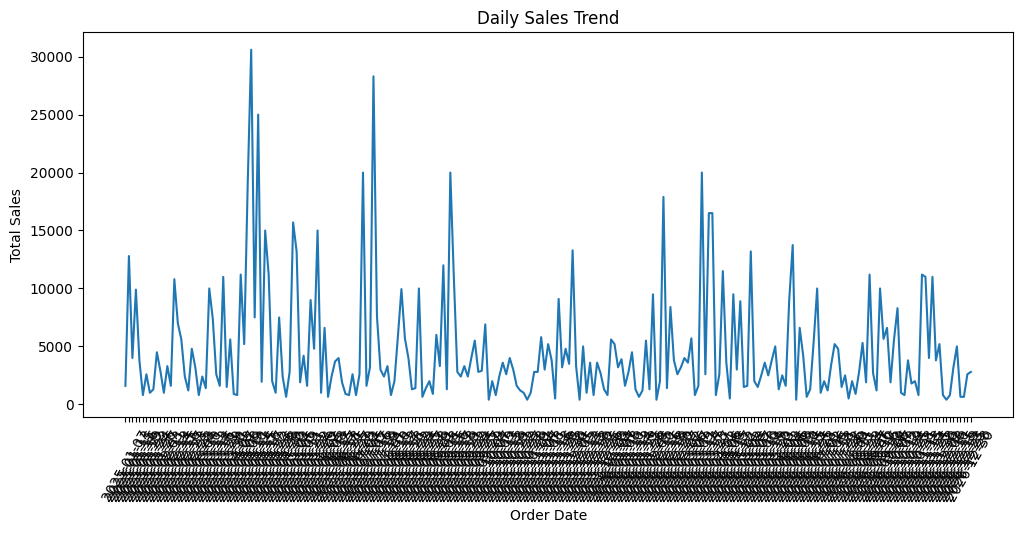

In [21]:
plt.figure(figsize=(12,5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title('Daily Sales Trend')
plt.xlabel('Order Date')
plt.ylabel('Total Sales')
plt.xticks(rotation=60)
plt.show()

In [22]:
print("Highest Sales Date:")
print(daily_sales.idxmax(), daily_sales.max())
print("Lowest Sales Date:")
print(daily_sales.idxmin(), daily_sales.min())

Highest Sales Date:
2025-04-14 30593
Lowest Sales Date:
2025-10-07 399


Task 2 – Category-wise Sales Comparison

In [23]:
category_sales = df.groupby('Category')['Sales'].sum()
print(category_sales)

Category
Beauty         129294
Books           58935
Electronics    386970
Fashion        206688
Home           345251
Name: Sales, dtype: int64


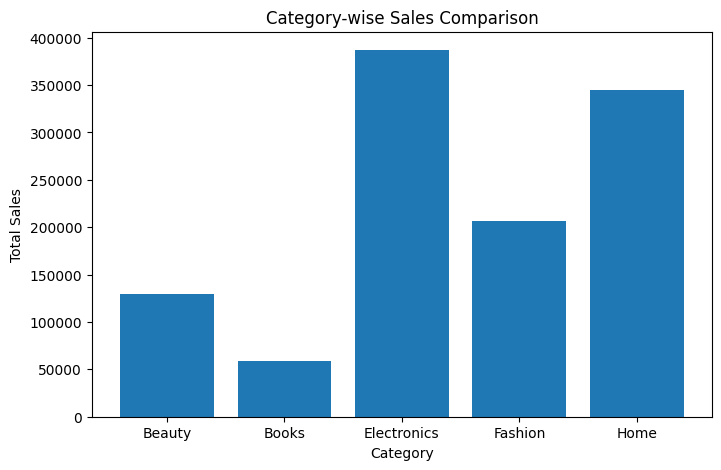

In [30]:
plt.figure(figsize=(8,5))
plt.bar(category_sales.index, category_sales.values)
plt.title('Category-wise Sales Comparison')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

Task 3 – City-wise Profit Analysis

In [31]:
city_profit = df.groupby('City')['Profit'].sum()
print(city_profit)

City
Ahmedabad    30620.51
Bengaluru    16176.91
Chennai      29064.40
Delhi        38333.71
Hyderabad    30631.64
Kolkata      31368.76
Mumbai       25173.78
Pune         10044.00
Name: Profit, dtype: float64


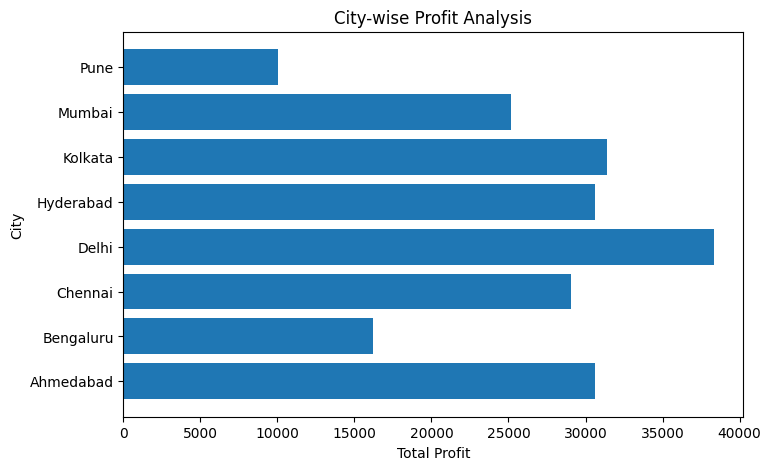

In [32]:
plt.figure(figsize=(8,5))
plt.barh(city_profit.index, city_profit.values)
plt.title('City-wise Profit Analysis')
plt.xlabel('Total Profit')
plt.ylabel('City')
plt.show()

In [33]:
print("Highest Profit City:")
print(city_profit.idxmax())
print("Highest Profit:")
print(city_profit.max())

Highest Profit City:
Delhi
Highest Profit:
38333.71


Task 4 – Quantity vs Sales Analysis

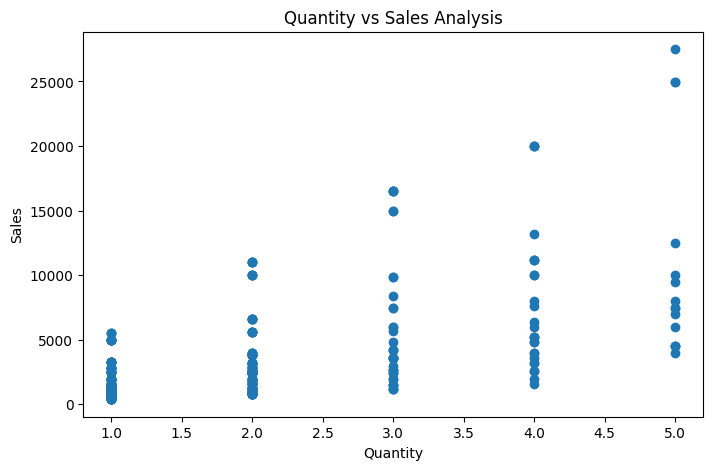

In [34]:
plt.figure(figsize=(8,5))
plt.scatter(df['Quantity'], df['Sales'])
plt.title('Quantity vs Sales Analysis')
plt.xlabel('Quantity')
plt.ylabel('Sales')
plt.show()

Task 5 – Sales Distribution Analysis

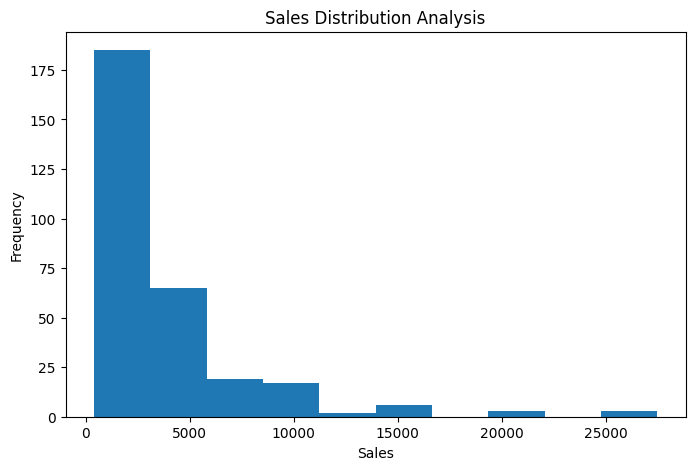

In [35]:
plt.figure(figsize=(8,5))
plt.hist(df['Sales'], bins=10)
plt.title('Sales Distribution Analysis')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

Task 6 – Category-wise Profit Contribution

In [36]:
category_profit = df.groupby('Category')['Profit'].sum()
print(category_profit)

Category
Beauty         34606.30
Books          14669.43
Electronics    54610.61
Fashion        52891.08
Home           54636.29
Name: Profit, dtype: float64


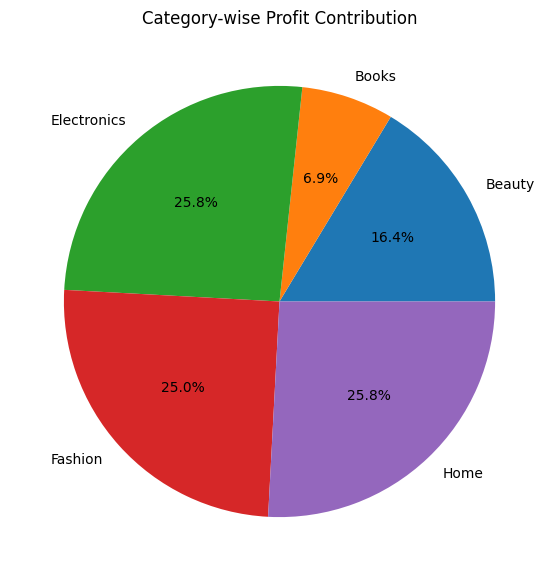

In [37]:
plt.figure(figsize=(7,7))
plt.pie(
    category_profit.values,
    labels=category_profit.index,
    autopct='%1.1f%%'
)
plt.title('Category-wise Profit Contribution')
plt.show()

In [40]:
print("Highest Profit Category:")
print(category_profit.idxmax())

Highest Profit Category:
Home


Task 7 – City-wise Order Analysis

In [41]:
city_orders = df.groupby('City')['Order_ID'].count()
print(city_orders)

City
Ahmedabad    38
Bengaluru    32
Chennai      31
Delhi        56
Hyderabad    44
Kolkata      39
Mumbai       32
Pune         28
Name: Order_ID, dtype: int64


In [42]:
city_percentage = (city_orders / city_orders.sum()) * 100
print(city_percentage)

City
Ahmedabad    12.666667
Bengaluru    10.666667
Chennai      10.333333
Delhi        18.666667
Hyderabad    14.666667
Kolkata      13.000000
Mumbai       10.666667
Pune          9.333333
Name: Order_ID, dtype: float64


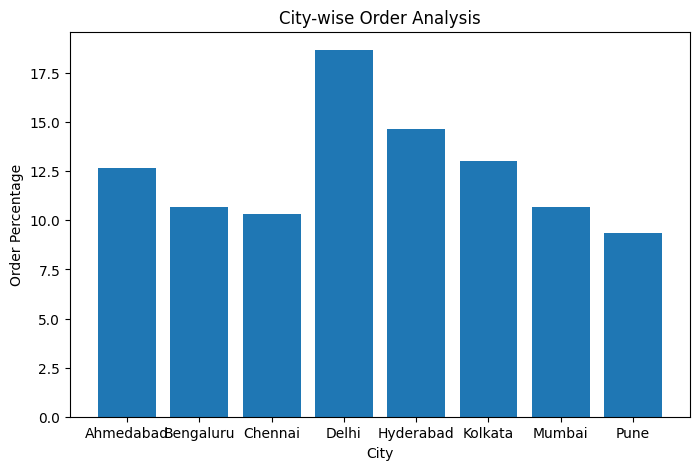

In [43]:
plt.figure(figsize=(8,5))
plt.bar(city_percentage.index, city_percentage.values)
plt.title('City-wise Order Analysis')
plt.xlabel('City')
plt.ylabel('Order Percentage')
plt.show()

Task 8 – Monthly Sales Analysis

In [45]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Month'] = df['Order_Date'].dt.month
monthly_sales = df.groupby('Month')['Sales'].sum()
print(monthly_sales)

Month
1      78497
2      87844
3     116349
4     175280
5      97899
6      91197
7      98652
8      64159
9     111297
10     61658
11     83753
12     60553
Name: Sales, dtype: int64


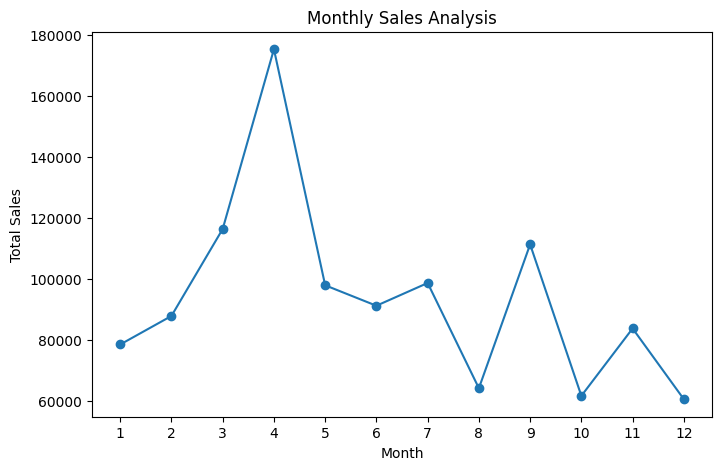

In [48]:
plt.figure(figsize=(8,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')
plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1,13))
plt.show()

Task 9 – Top 5 Best-selling Products

In [49]:
product_sales = df.groupby('Product_Name')['Quantity'].sum()
print(product_sales)

Product_Name
Air Fryer            28
Backpack             24
Bedsheet Set         51
Bluetooth Speaker    31
Cookbook             39
Cookware Set         28
Denim Jacket         28
Face Serum           43
Hair Dryer           29
Novel                43
Perfume              34
Power Bank           27
Running Shoes        32
Self-Help Book       33
Smartwatch           44
Sunglasses           28
Table Lamp           42
Wireless Earbuds     28
Name: Quantity, dtype: int64


In [50]:
top_5 = product_sales.sort_values(ascending=False).head(5)
print(top_5)

Product_Name
Bedsheet Set    51
Smartwatch      44
Novel           43
Face Serum      43
Table Lamp      42
Name: Quantity, dtype: int64


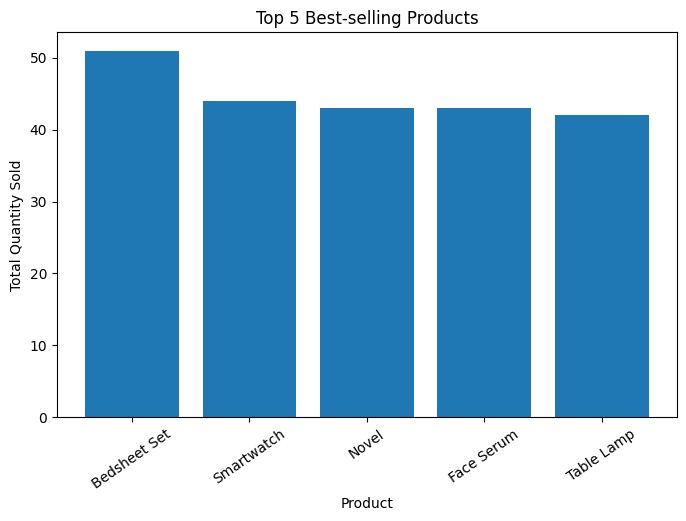

In [53]:
plt.figure(figsize=(8,5))
plt.bar(top_5.index, top_5.values)
plt.title('Top 5 Best-selling Products')
plt.xlabel('Product')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=35)
plt.show()

Task 10 – Category-wise Sales Distribution

/tmp/ipykernel_653/3085851479.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(sales_data, labels=categories)


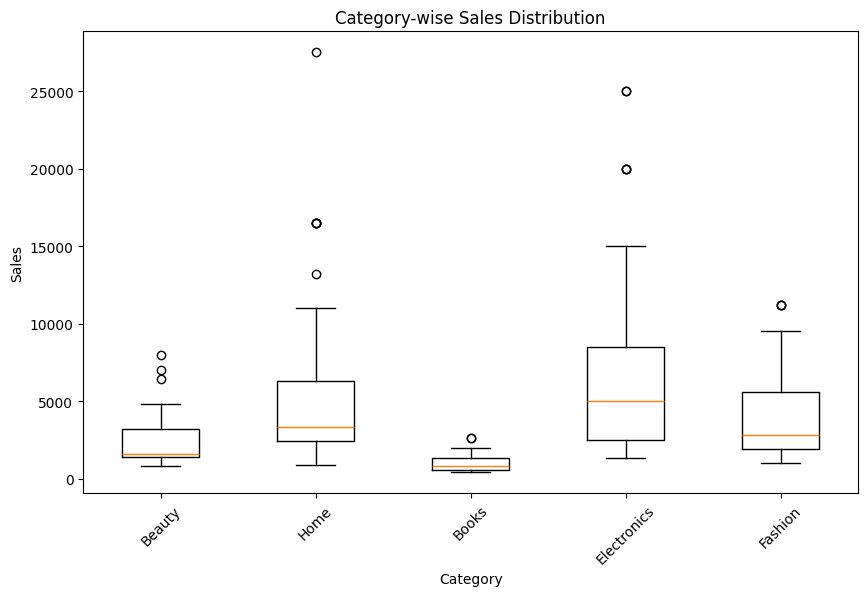

In [54]:
categories = df['Category'].unique()
sales_data = []
for category in categories:
    sales = df[df['Category'] == category]['Sales']
    sales_data.append(sales)
plt.figure(figsize=(10,6))
plt.boxplot(sales_data, labels=categories)
plt.title('Category-wise Sales Distribution')
plt.xlabel('Category')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.show()

CONCLUSION : In This Mini Project, I Performed Sales Data Analysis Using Python libraries Pandas and Matplotlib.I Analyzed Daily Sales,Category-Wise Profit,Quantity and Sales Relationships,Sales Distribution,Monthly Sales and Top-Selling Products.I Used Different Visualizations Such as Line Plots, Bar Plots,Scatter Plots,Histograms,Pie Charts and Box Plots.This Project Helped me Understand Sales Patterns and Gain Practical Experience in Data Analysis and Visualization.